# ARCSIX Zenith Cloud Retrieval — 2024-06-07

**Purpose:** Run the 15-parameter zenith cloud property retrieval on ARCSIX 4STAR-B zenith radiances for the 2024-06-07 flight.  
Applies the spectral cloud retrieval from [LeBlanc et al., 2015, AMT].  
Input radiances come from the SSRR processed HDF5 file; the LUT was built with Prepare/Read_save_ARCSIX_lut.

**Input files:**
- `/data2/ARCSIX/data/ARCSIX-SSRR_P3B_20240607_v2.h5` — zenith radiance (19627 × 425 wvl)
- `/data2/ARCSIX/data/v1_ARCSIX_lut.mat` — look-up table (phase × wvl × zout × ref × tau × sza)

**Key differences from ORACLES workflow:**
- Radiances in HDF5 (`zen/rad`, `zen/wvl`) not MATLAB starzen
- Time stored as `tmhr` (UTC decimal hours) not MATLAB serial time
- 425 wavelengths (352–2197 nm); `param()` threshold lowered to 300 in Sp_parameters.py
- Both liquid and ice phases enabled (Arctic campaign)

## Imports

In [1]:
import numpy as np
import h5py
import os
import matplotlib
matplotlib.rc_file('file.rc')
import matplotlib.pyplot as plt
#%matplotlib notebook
import scipy.io as sio
import Sp_parameters as Sp
import run_kisq_retrieval as rk
try:
    xrange
except NameError:
    xrange = range

In [2]:
%matplotlib ipympl

## Paths and settings

In [ ]:
datestr = '20240607'

fp_h5    = '/data2/ARCSIX/data/ARCSIX-SSRR_P3B_{}_v2.h5'.format(datestr)
fp_lut   = '/data2/ARCSIX/data/v1_ARCSIX_lut.mat'
fp_out   = '/data2/ARCSIX/data/'
fp_plots = '/data2/ARCSIX/plot/'

if not os.path.isdir(fp_plots):
    os.makedirs(fp_plots)

# Retrieval settings
forceliq  = False   # True = liquid only; False = both phases
forceice  = False   # True = ice only
iz        = 0       # zout altitude index (0 = lowest)
norm_1050 = True    # normalize spectra to 1040-1050 nm region
start_tau = 0.1
end_tau   = 60.0
start_ref = 2.0
end_ref   = 60.0
no_filter = False   # if True, skip the spectral smoothness filter

## Load ARCSIX HDF5 data

In [4]:
print('Loading {}'.format(fp_h5))
with h5py.File(fp_h5, 'r') as f:
    rad_raw = f['zen/rad'][()]   # (ntime, nwvl) zenith radiance [W/m2/nm/sr]
    wvl_raw = f['zen/wvl'][()]   # (nwvl,) wavelengths [nm]
    tmhr    = f['tmhr'][()]      # UTC decimal hours
    sza_raw = f['sza'][()]       # solar zenith angle [deg]
    lat_raw = f['lat'][()]       # latitude [deg N]
    lon_raw = f['lon'][()]       # longitude [deg E]
    alt_raw = f['alt'][()]       # altitude [m MSL]

print('Raw rad shape: {}, wvl range: {:.1f}--{:.1f} nm'.format(
    rad_raw.shape, wvl_raw.min(), wvl_raw.max()))
print('Time range: {:.4f}--{:.4f} UTC hours'.format(tmhr.min(), tmhr.max()))
print('SZA range:  {:.2f}--{:.2f} deg'.format(sza_raw.min(), sza_raw.max()))

Loading /data2/ARCSIX/data/ARCSIX-SSRR_P3B_20240607_v2.h5
Raw rad shape: (19627, 425), wvl range: 352.3--2197.2 nm
Time range: 13.3178--18.7694 UTC hours
SZA range:  55.92--62.51 deg


## Clean and pre-filter data

Replace physically invalid (negative) radiance values with NaN.  
Remove time steps where the entire spectrum is bad (all-NaN rows, e.g. instrument off) so they
are excluded from the retrieval without distorting the geolocation arrays.

In [5]:
rad = rad_raw.copy()

# Negative radiance is unphysical (noise in strong water-vapour absorption bands)
rad[rad < 0] = np.nan

# Valid rows: first wavelength must be finite and positive
valid = np.isfinite(rad[:, 0])
print('Valid rows: {:d} / {:d}  ({:d} removed)'.format(
    valid.sum(), len(valid), (~valid).sum()))

rad_v  = rad[valid, :]
tmhr_v = tmhr[valid]
sza_v  = sza_raw[valid]
lat_v  = lat_raw[valid]
lon_v  = lon_raw[valid]
alt_v  = alt_raw[valid]

print('Cleaned rad shape:', rad_v.shape)
print('Mean valid wavelengths per row: {:.1f} / {:d}'.format(
    np.sum(np.isfinite(rad_v), axis=1).mean(), rad_v.shape[1]))

Valid rows: 18639 / 19627  (988 removed)
Cleaned rad shape: (18639, 425)
Mean valid wavelengths per row: 393.1 / 425


# Build measurement dict and create Sp object

`Sp.Sp()` expects the following keys:
- `wvl`: 1-D wavelength array
- `rad`: radiance array (ntime × nwvl)
- `utc`: UTC time in decimal hours
- `sza`, `Alt`, `Lat`, `Lon`: geolocation (note capital A/L/L)

In [6]:
mea = {
    'wvl': wvl_raw,
    'rad': rad_v,
    'utc': tmhr_v,
    'sza': sza_v,
    'Alt': alt_v,
    'Lat': lat_v,
    'Lon': lon_v,
}

meas = Sp.Sp(mea, verbose=False)
meas.datestr = datestr
print('Sp object ready.  sp shape: {}  wvl: {:.1f}--{:.1f} nm'.format(
    meas.sp.shape, meas.wvl.min(), meas.wvl.max()))

Sp object ready.  sp shape: (18639, 425)  wvl: 352.3--2197.2 nm


In [7]:
print('Computing spectral parameters...')
meas.params(norm_1050=norm_1050)
print('par shape:', meas.par.shape)
print('NaN fraction in par[:,0]: {:.1%}'.format(np.isnan(meas.par[:, 0]).mean()))

Computing spectral parameters...
par shape: (18639, 16)
NaN fraction in par[:,0]: 0.3%


## Plots — measured zenith radiance spectra

In [8]:
matplotlib.rcParams['text.usetex'] = False

In [9]:
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial']

Saved zenrad figure


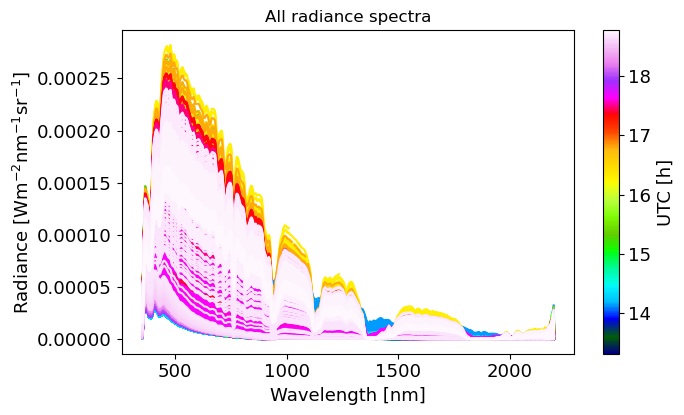

In [10]:
fig1 = Sp.plt_zenrad(meas)
fig1.savefig(fp_plots + '{}_zenrad.png'.format(datestr), dpi=150, transparent=True)
print('Saved zenrad figure')

Saved norm zenrad figure


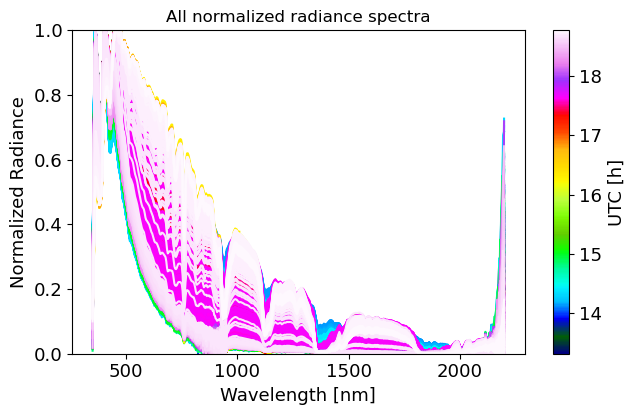

In [11]:
fig1n = Sp.plt_norm_zenrad(meas)
fig1n.savefig(fp_plots + '{}_norm_zenrad.png'.format(datestr), dpi=150, transparent=True)
print('Saved norm zenrad figure')

Saved UTC curtain zenrad figure


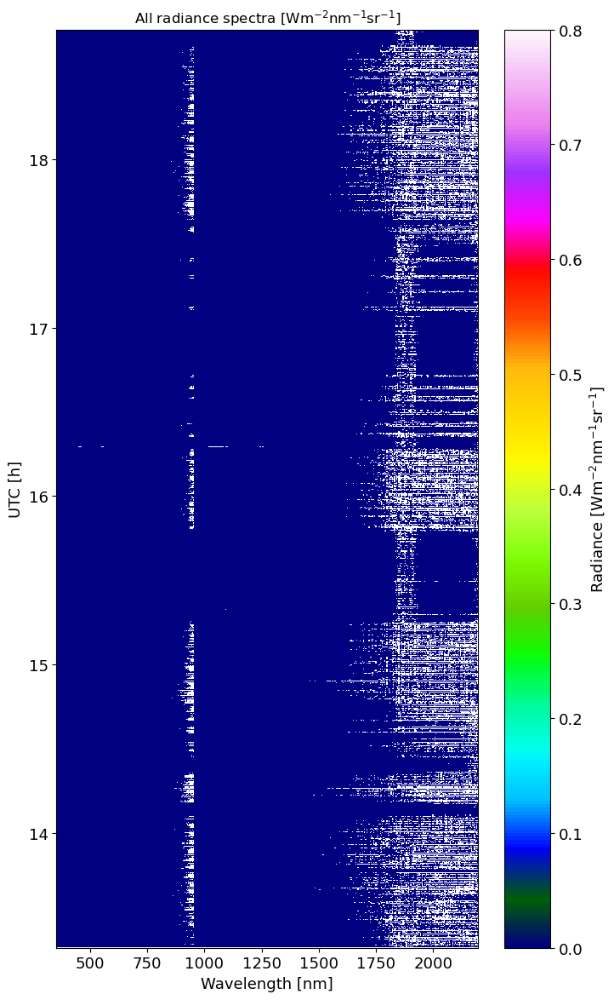

In [12]:
fig2 = Sp.curtain_zenrad(meas, utc=True)
fig2.savefig(fp_plots + '{}_curtain_utc_zenrad.png'.format(datestr), dpi=150, transparent=True)
print('Saved UTC curtain zenrad figure')

Saved UTC curtain norm zenrad figure


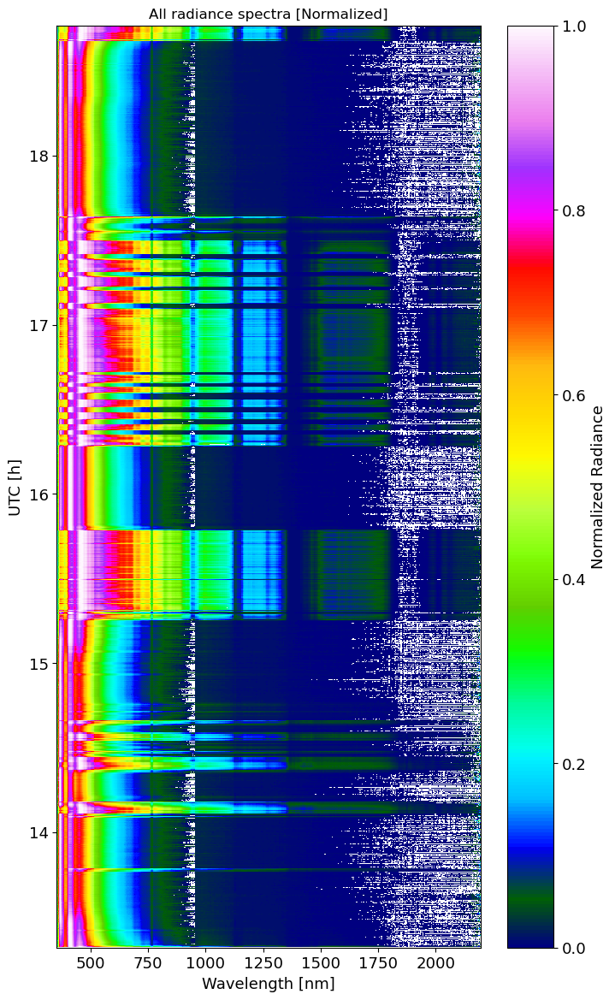

In [13]:
fig2n = Sp.curtain_norm_zenrad(meas, utc=True)
fig2n.savefig(fp_plots + '{}_curtain_utc_norm_zenrad.png'.format(datestr), dpi=150, transparent=True)
print('Saved UTC curtain norm zenrad figure')

Saved index-axis curtain figures


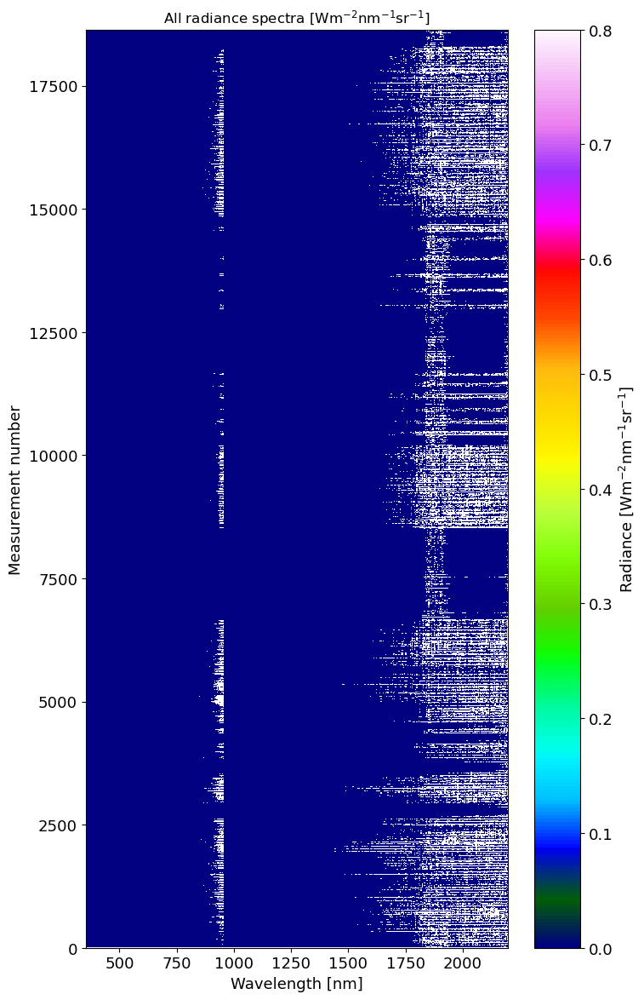

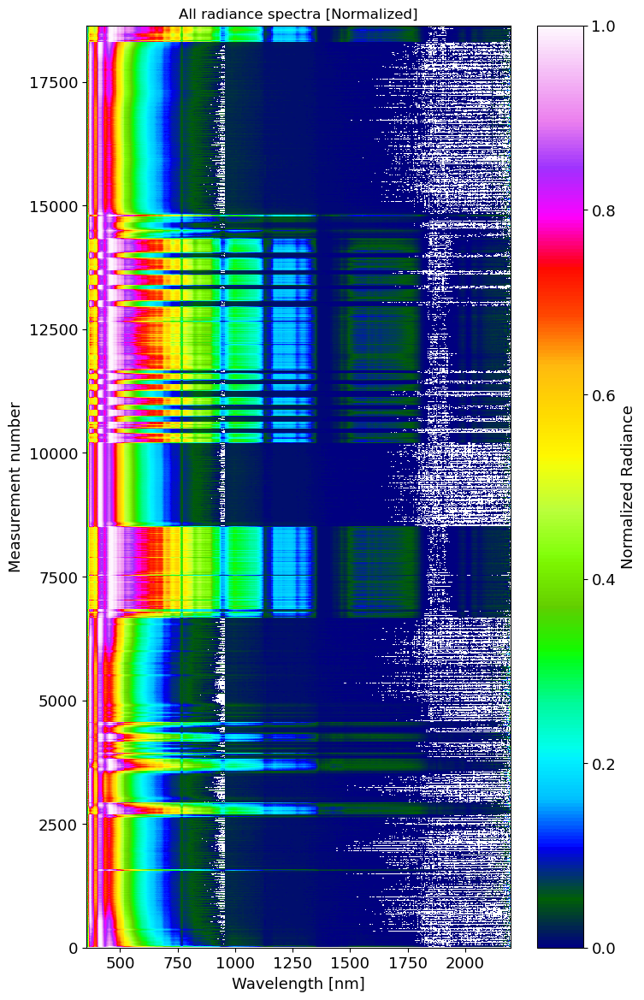

In [14]:
fig3 = Sp.curtain_zenrad(meas, utc=False)
fig3.savefig(fp_plots + '{}_curtain_zenrad.png'.format(datestr), dpi=150, transparent=True)

fig3n = Sp.curtain_norm_zenrad(meas, utc=False)
fig3n.savefig(fp_plots + '{}_curtain_norm_zenrad.png'.format(datestr), dpi=150, transparent=True)
print('Saved index-axis curtain figures')

# Load Look-Up Table

`scipy.io.loadmat` returns MATLAB row vectors as shape `(1, N)`.  
Ravel the 1-D variables after loading so that `Sp.Sp()` receives clean 1-D arrays.

In [15]:
print('Loading LUT:', fp_lut)
luts = sio.loadmat(fp_lut)

# Ravel 1-D variables that scipy.io returns as (1, N)
for key in ['wvl', 'sza', 'tau', 'ref', 'zout']:
    luts[key] = luts[key].ravel()

print('LUT rad shape:', luts['rad'].shape,
      ' (phase x wvl x zout x ref x tau x sza)')
print('SZA values:', luts['sza'])
print('tau range:  {:.2f} -- {:.2f}'.format(luts['tau'].min(), luts['tau'].max()))
print('ref range:  {:.1f} -- {:.1f} um'.format(luts['ref'].min(), luts['ref'].max()))
print('wvl range:  {:.1f} -- {:.1f} nm ({:d} pts)'.format(
    luts['wvl'].min(), luts['wvl'].max(), len(luts['wvl'])))

Loading LUT: /data2/ARCSIX/data/v1_ARCSIX_lut.mat
LUT rad shape: (2, 1302, 3, 28, 34, 6)  (phase x wvl x zout x ref x tau x sza)
SZA values: [60.  60.5 61.  61.5 62.  62.5]
tau range:  0.10 -- 60.00
ref range:  2.0 -- 60.0 um
wvl range:  400.0 -- 1700.0 nm (1302 pts)


## Build LUT Sp objects for each SZA

In [16]:
airmass = 1.0 / np.cos(luts['sza'] * np.pi / 180.0)

meas.airmass = 1.0 / np.cos(meas.sza * np.pi / 180.0)
if len(airmass) > 1:
    idx = Sp.find_closest(airmass, meas.airmass)
else:
    print('*** Only one airmass in LUT: {:.4f} ***'.format(airmass[0]))
    idx = np.zeros_like(meas.airmass, dtype=int)

print('SZA index histogram:', np.bincount(idx))

SZA index histogram: [8814 1645 2138 2458 2581 1003]


In [17]:
lut = []
nsza = len(luts['sza'])
print('Building LUT params for {:d} SZA values...'.format(nsza))

for s in xrange(nsza):
    sptemp = {
        'tau':         luts['tau'],
        'ref':         luts['ref'],
        'zout':        luts['zout'],
        'sza':         luts['sza'],
        'phase':       luts['phase'],
        'irr_dn_diff': luts['irr_dn_diff'][:, :, :, :, :, s],
        'irr_dn':      luts['irr_dn'][:, :, :, :, :, s],
        'irr_up':      luts['irr_up'][:, :, :, :, :, s],
        'wvl':         [luts['wvl']],   # Sp.Sp() expects a list wrapping the array
        'rad':         luts['rad'][:, :, :, :, :, s],
    }
    ltemp = Sp.Sp(sptemp, verbose=False)
    if s in idx:
        ltemp.params(liq_only=forceliq, ice_only=forceice, iz=iz, norm_1050=norm_1050)
        ltemp.param_hires(
            start_ref=start_ref, end_ref=end_ref,
            start_tau=start_tau, end_tau=end_tau)
    lut.append(ltemp)
    print('  SZA {:.1f} deg -- done'.format(luts['sza'][s]))

print('LUT ready.')

Building LUT params for 6 SZA values...
Running interpolation on params: [########################################]100% -- Done! 
  SZA 60.0 deg -- done
Running interpolation on params: [########################################]100% -- Done! 
  SZA 60.5 deg -- done
Running interpolation on params: [########################################]100% -- Done! 
  SZA 61.0 deg -- done
Running interpolation on params: [########################################]100% -- Done! 
  SZA 61.5 deg -- done
Running interpolation on params: [########################################]100% -- Done! 
  SZA 62.0 deg -- done
Running interpolation on params: [########################################]100% -- Done! 
  SZA 62.5 deg -- done
LUT ready.


## Plot out the LUT per sza

In [18]:
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial']

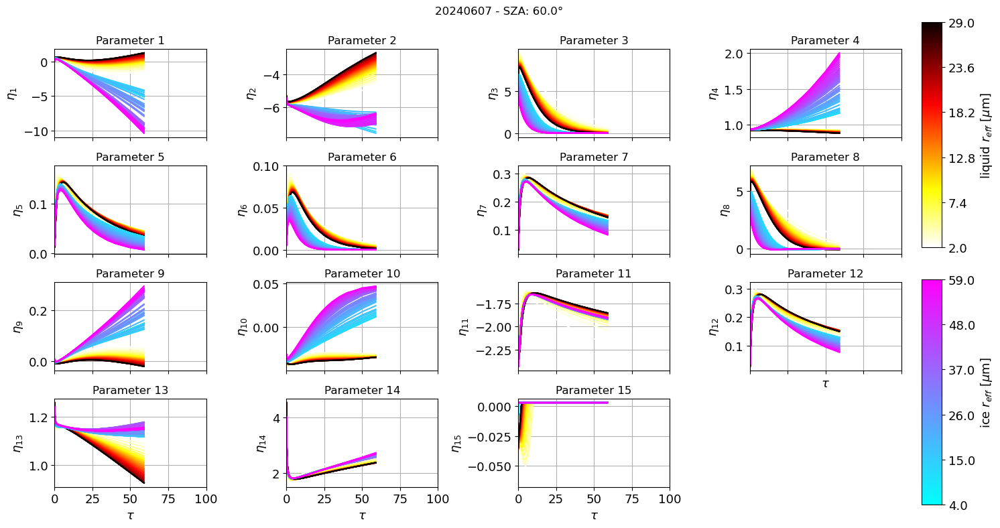

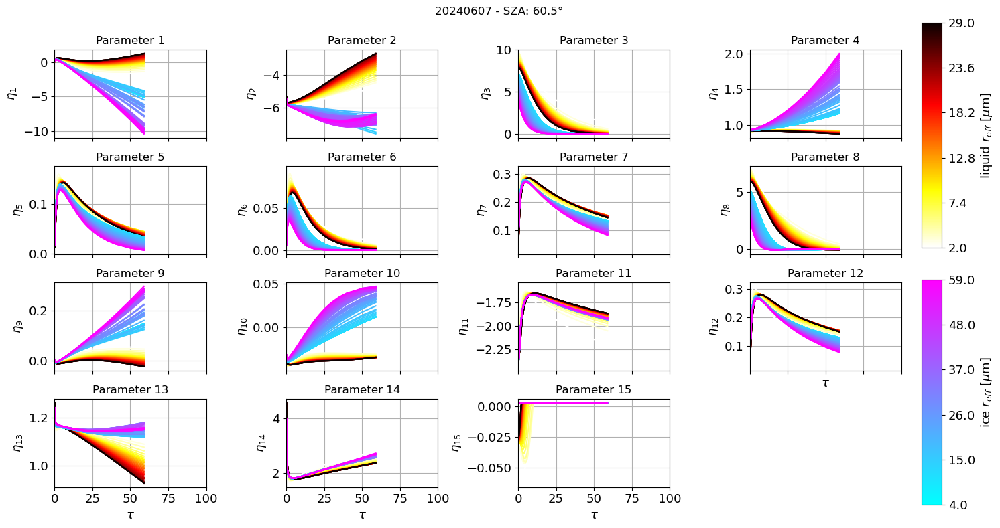

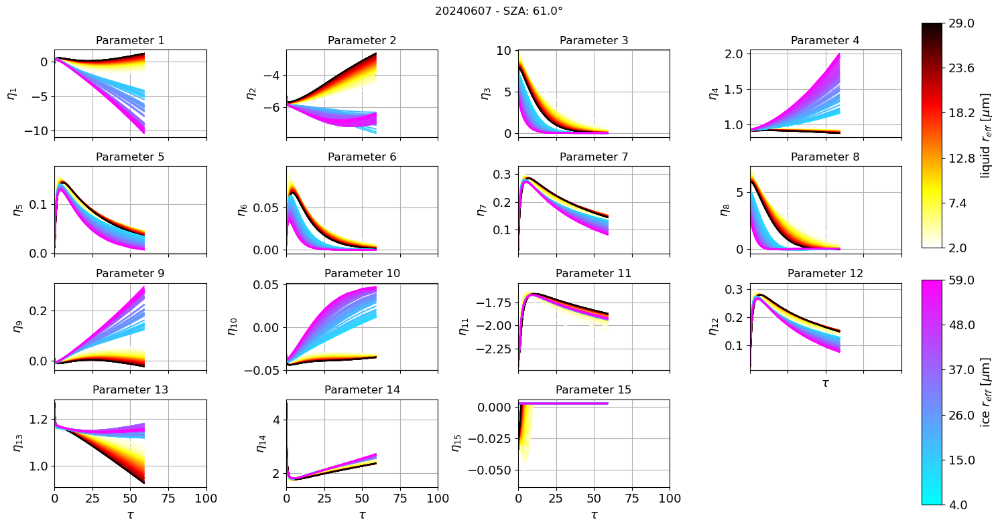

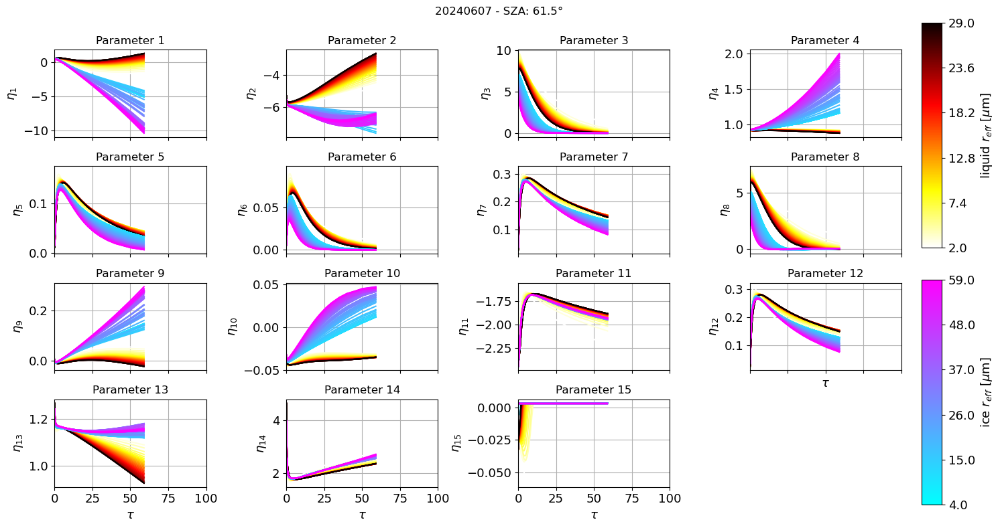

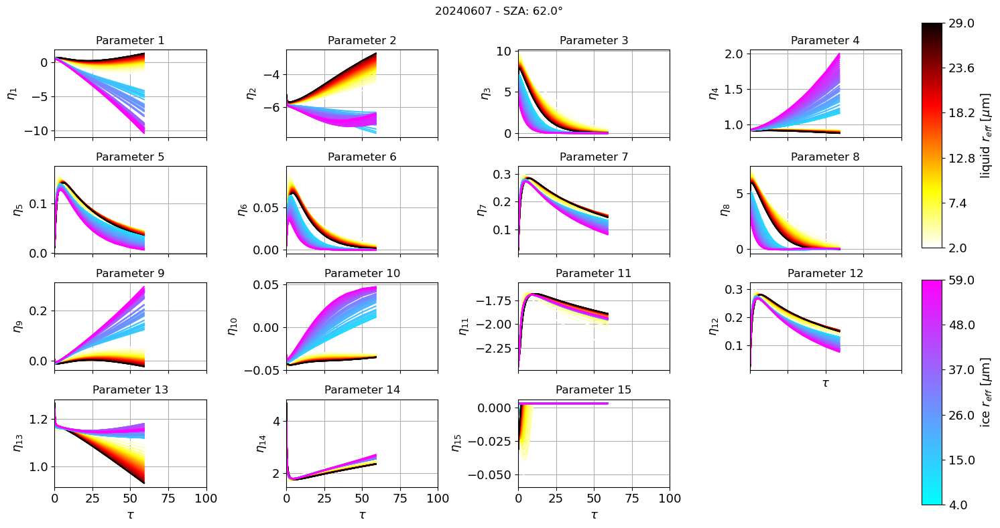

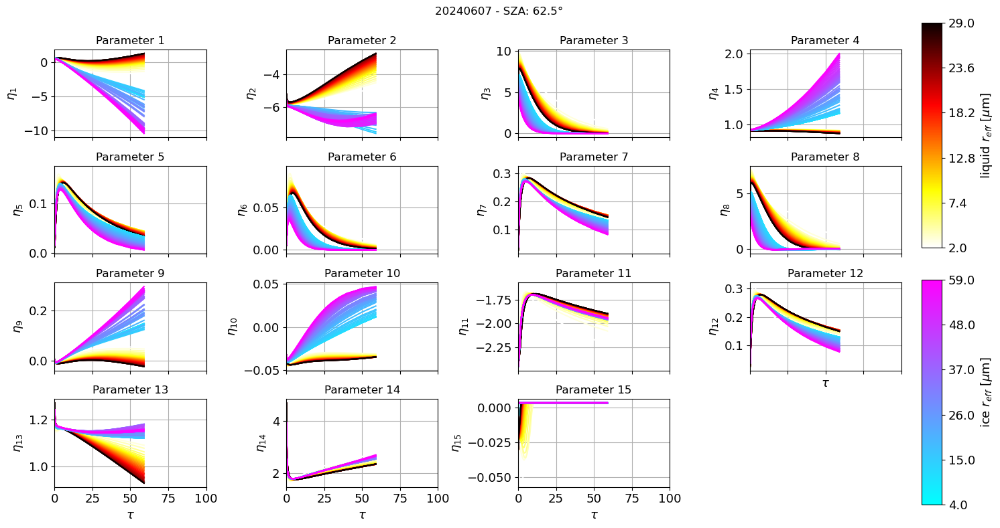

In [25]:
for i,ll in enumerate(lut):
    if len(lut[i].par)>4:
        continue
    if not i in np.unique(idx):
        continue
    try: 
        figl,axl = Sp.plot_lut_vs_tau(lut[i],forceliq=forceliq,forceice=forceice)
        figl.suptitle(f"{datestr} - SZA: {ll['sza'][i]}°")#,verticalalignment='bottom')
        figl.savefig(fp_plots+'{datestr}_lut_only_sza_{sza:02.1f}.png'.format(datestr=datestr,sza=ll['sza'][i]),
                     dpi=600,transparent=True)
    except Exception as ie:
        print('*** Problem with plotting of sza:{sza:02.1f}'.format(sza=ll['sza'][i]))
        print(f'*** Error: {ie}')

# Run the retrieval

Loop over unique airmass (SZA) bins.  
Within each bin, apply a spectral smoothness filter that rejects spectra with an abrupt jump
near the ~981 nm Si/InGaAs detector boundary, then run the KiSQ retrieval.

In [26]:
# Wavelength indices for the spectral smoothness filter
i_flt1 = np.argmin(np.abs(meas.wvl - 981.0))
i_flt2 = np.argmin(np.abs(meas.wvl - 982.0))
print('Filter wavelengths: {:.1f} nm (idx {:d}) and {:.1f} nm (idx {:d})'.format(
    meas.wvl[i_flt1], i_flt1, meas.wvl[i_flt2], i_flt2))

(meas.taut, meas.ref, meas.phase, meas.ki) = (
    np.zeros_like(meas.utc) * np.nan,
    np.zeros_like(meas.utc) * np.nan,
    np.zeros_like(meas.utc) * np.nan,
    np.zeros_like(meas.utc) * np.nan,
)

Filter wavelengths: 978.9 nm (idx 185) and 978.9 nm (idx 185)


In [27]:
print('Running retrieval...')

for i in np.unique(idx):
    am_val  = airmass[i]
    sza_val = luts['sza'][i]
    meas.good = np.where(idx == i)[0]

    if not no_filter:
        sss = np.abs(meas.norm[meas.good, i_flt1] - meas.norm[meas.good, i_flt2])
        meas.good = meas.good[sss < 0.1]

    print('  SZA={:.1f} airmass={:.3f} -- {:d} good points'.format(
        sza_val, am_val, len(meas.good)))

    if len(meas.good) == 0:
        continue

    tau, ref, phase, ki = rk.run_retrieval(meas, lut[i],
                                            force_liq=forceliq, force_ice=forceice)
    meas.taut[meas.good]  = tau[meas.good]
    meas.ref[meas.good]   = ref[meas.good]
    meas.phase[meas.good] = phase[meas.good]
    meas.ki[meas.good]    = ki[meas.good]

meas.tau = meas.taut
print('Done.  Valid tau retrievals: {:d}'.format(int(np.sum(np.isfinite(meas.tau)))))

Running retrieval...
  SZA=60.0 airmass=2.000 -- 8814 good points
Retrieval progress over times: [########################################]100% -- Done! 
  SZA=60.5 airmass=2.031 -- 1645 good points
Retrieval progress over times: [########################################]100% -- Done! 
  SZA=61.0 airmass=2.063 -- 2138 good points
Retrieval progress over times: [########################################]100% -- Done! 
  SZA=61.5 airmass=2.096 -- 2458 good points
Retrieval progress over times: [########################################]100% -- Done! 
  SZA=62.0 airmass=2.130 -- 2581 good points
Retrieval progress over times: [########################################]100% -- Done! 
  SZA=62.5 airmass=2.166 -- 1003 good points
Retrieval progress over times: [########################################]100% -- Done! 
Done.  Valid tau retrievals: 18583


## Save retrieval results

In [28]:
fp_save = os.path.join(fp_out, '{}_zen_cld_retrieved.mat'.format(datestr))
mdict = {
    'tau':   meas.tau,
    'ref':   meas.ref,
    'phase': meas.phase,
    'ki':    meas.ki,
    'utc':   meas.utc,
    'sza':   meas.sza,
    'lat':   meas.lat,
    'lon':   meas.lon,
    'alt':   meas.alt,
}
sio.savemat(fp_save, mdict)
print('Saved:', fp_save)

Saved: /data2/ARCSIX/data/20240607_zen_cld_retrieved.mat


# Retrieval plots

In [67]:
figz.axes

[<Axes: title={'center': 'Retrieval results time trace'}, ylabel='$\\tau$'>,
 <Axes: ylabel='R$_{ef}$ [$\\mu$m]'>,
 <Axes: ylabel='Phase'>,
 <Axes: xlabel='UTC [Hours]', ylabel='$\\chi^{2}$'>]

Plotting retrieval time series...


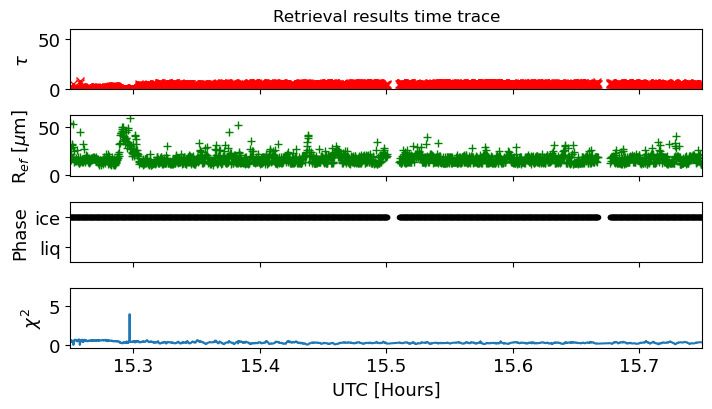

In [29]:
print('Plotting retrieval time series...')
figz = Sp.plot_zen_cld_retrieval(meas)
plt.xlim(15.25,15.75)
figz.savefig(fp_plots + '{}_retrieval_out.png'.format(datestr), dpi=150, transparent=True)

In [95]:
import matplotlib.gridspec as gridspec

# 1. Grab the 4 existing axes from the figure
ax1, ax2, ax3, ax4 = figz.axes

# 2. Define a new 3-row GridSpec with custom height ratios
gs = gridspec.GridSpec(3, 1, figure=figz, height_ratios=[2, 2, 1.2], hspace=0.12)

# 3. Reposition the top two axes
ax1.set_subplotspec(gs[0])
ax2.set_subplotspec(gs[1])

ax1.set_ylim(0,10)
ax2.set_ylim(5,50)
ax1.grid(visible=True)
ax2.grid(visible=True)

# 4. Stack ax3 and ax4 into the exact same 3rd GridSpec slot
ax3.set_subplotspec(gs[2])
ax4.set_subplotspec(gs[2])

# 5. Turn ax4 into a "right-axis" overlay on top of ax3
ax4.patch.set_visible(False)  # Make ax4 background transparent so ax3 shows through
ax4.yaxis.tick_right()  # Move y-ticks to the right
ax4.yaxis.set_label_position('right')  # Move y-label to the right
ax4.spines['right'].set_visible(True)  # Ensure right spine is drawn
ax4.spines['left'].set_visible(False)  # Hide left spine so it doesn't clash with ax3
ax4.spines['top'].set_visible(False)
ax4.spines['bottom'].set_visible(False)
ax3.xaxis.set_visible(False)  # Hide duplicate x-axis ticks/labels on ax4
ax4.xaxis.set_visible(True) 

# 6. Optional: Clean up x-tick labels on ax1 and ax2 if sharing x-axis
ax1.tick_params(labelbottom=False)
ax2.tick_params(labelbottom=False)

ax1.set_title(f'{datestr} - cloud zenith retrievals from P-3B')
ax4.yaxis.label.set_color('tab:blue')
ax4.tick_params(axis='y', labelcolor='tab:blue')
ax4.set_ylim(0,1)
figz.subplots_adjust(right=0.88)
figz.canvas.draw_idle()

figz.savefig(fp_plots + '{}_retrieval_out.png'.format(datestr), dpi=150, transparent=True)

In [52]:
# ensure inputs to histograms
fl = (meas.utc>flt[0]) & (meas.utc<flt[1])
meas.tau_m, meas.taui = Sp.nanmasked(meas.tau[fl])
meas.ref_m, meas.refi = Sp.nanmasked(meas.ref[fl])
meas.phase_m, meas.phasei = Sp.nanmasked(meas.phase[fl])

In [55]:
meas.phase_m

array([1., 1., 1., ..., 1., 1., 1.], shape=(2091,))

Trying the more natural plotting


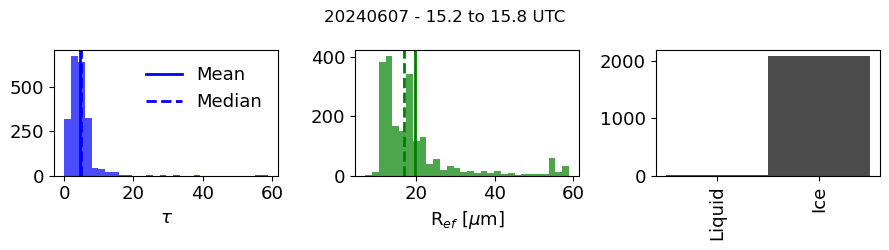

In [89]:
print('Trying the more natural plotting')

fig = plt.figure(figsize=(9,2.5))
plt.subplot(1,3,1)
n,bins,p = plt.hist(meas.tau_m,30,histtype='stepfilled', alpha=0.7,color='b')
plt.axvline(np.nanmean(meas.tau_m),label='Mean',color='b',lw=2)
plt.axvline(np.median(meas.tau_m),linestyle='--',label='Median',color='b',lw=2)
plt.xlabel('$\\tau$')
plt.legend(frameon=False)

plt.subplot(1,3,2)
n,bins,p = plt.hist(meas.ref_m,30,histtype='stepfilled', alpha=0.7,color='g')
plt.axvline(np.nanmean(meas.ref_m),color='g',lw=2)
plt.axvline(np.median(meas.ref_m),color='g',linestyle='--',lw=2)
plt.xlabel('R$_{ef}$ [$\\mu$m]')

plt.subplot(1,3,3)
n,bins,p = plt.hist(meas.phase_m,bins=[-1.0,0.0001,1.0],histtype='stepfilled', alpha=0.7,color='k')
#plt.ylim([0,1.1])
plt.xlim([-1.1,1.1])
plt.xticks([-0.5,0.5],['Liquid','Ice'],rotation='vertical')
plt.suptitle(f'{datestr} - {flt[0]} to {flt[1]} UTC')
plt.tight_layout()
figz.savefig(fp_plots + '{}_retrieval_histogram.png'.format(datestr), dpi=150, transparent=True)

Plotting flight-track map...


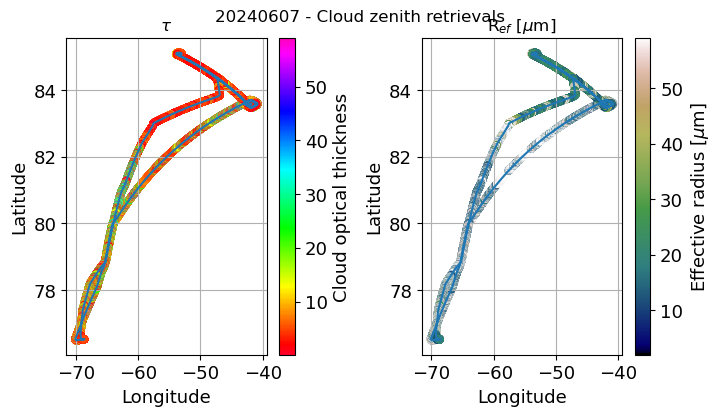

In [61]:
print('Plotting flight-track map...')
figm = Sp.plot_map_cld_retrieval(meas)
figm.suptitle(f'{datestr} - zenith retrievals')
figm.savefig(fp_plots + '{}_map_retr_zencld.png'.format(datestr), dpi=150, transparent=True)

## Plot out retrieal on top of LUT

In [32]:
meas.keys()

dict_keys(['verbose', 'wvl', 'iwvls', 'iset', 'sp', 'isubwvl', 'norm', 'utc', 'datestr', 'good', 'alt', 'lat', 'lon', 'sza', 'npar', 'par', 'parn', 'meansp', 'stdsp', 'stdpar', 'stdparn', 'sphires', 'parhires', 'hiresirrad', 'irrad', 'reflect', 'param', 'airmass', 'taut', 'ref', 'phase', 'ki', 'parn_ice', 'parn_liq', 'tau', 'tau_m', 'taui', 'ref_m', 'refi', 'phase_m', 'phasei'])

In [37]:
ik.shape

(18639,)

In [36]:
meas.par.shape

(18639, 16)

In [40]:
flt = [15.2,15.8]

In [42]:
(meas.utc>flt[0]) & (meas.utc<flt[1])

array([False, False, False, ..., False, False, False], shape=(18639,))

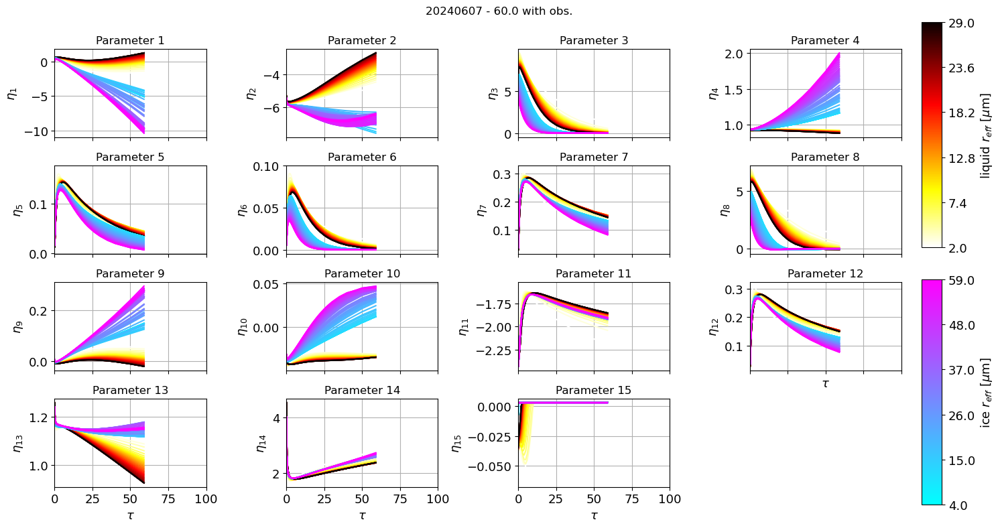

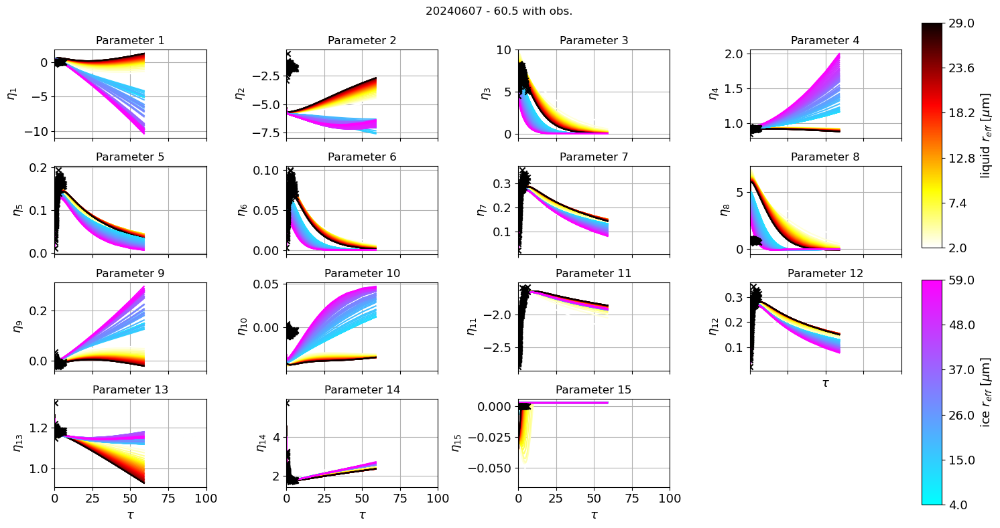

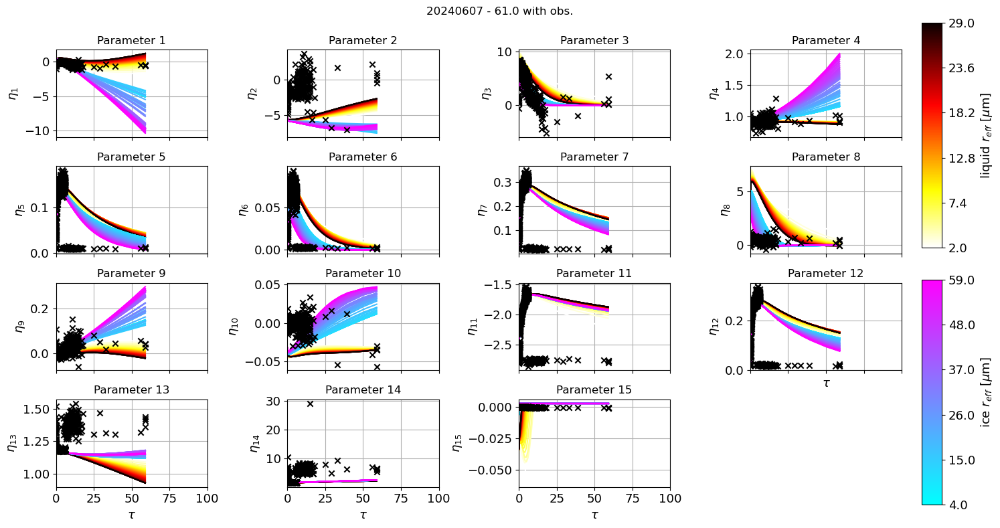

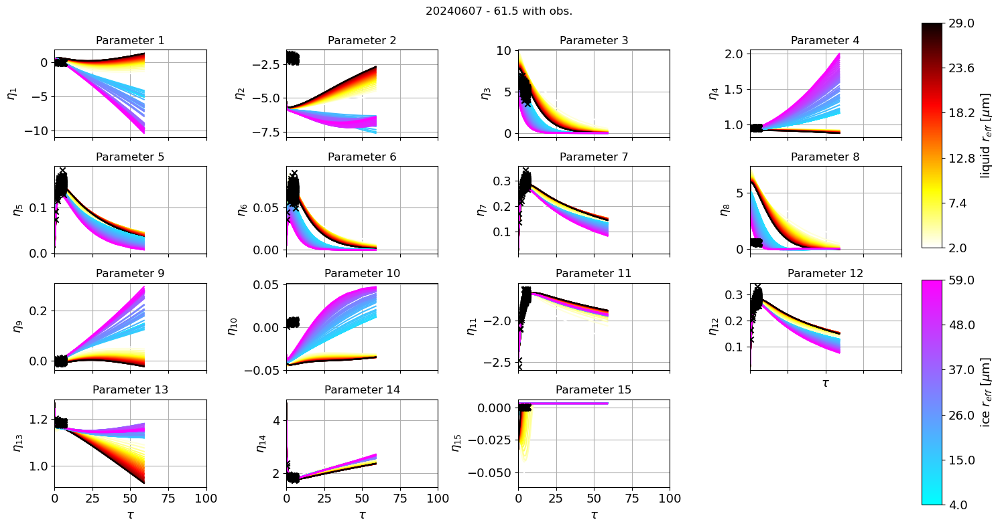

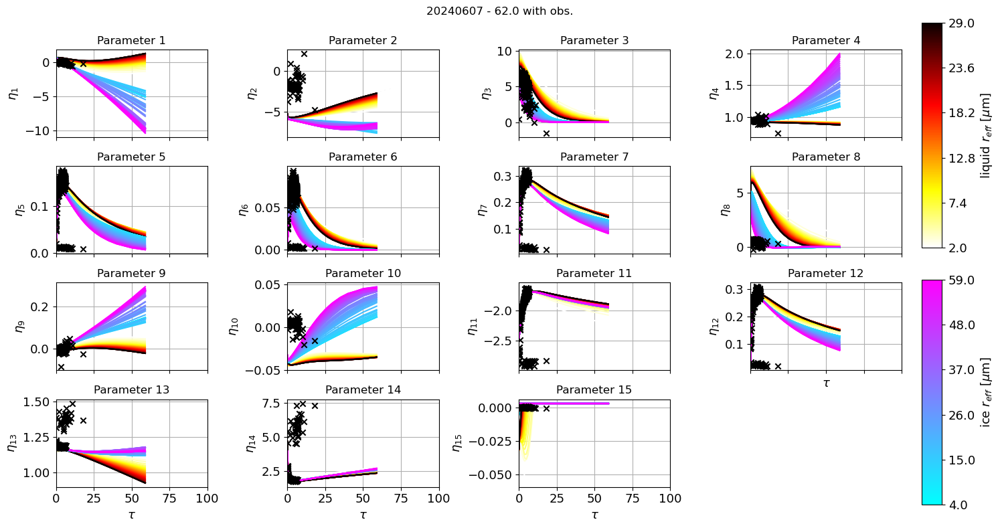

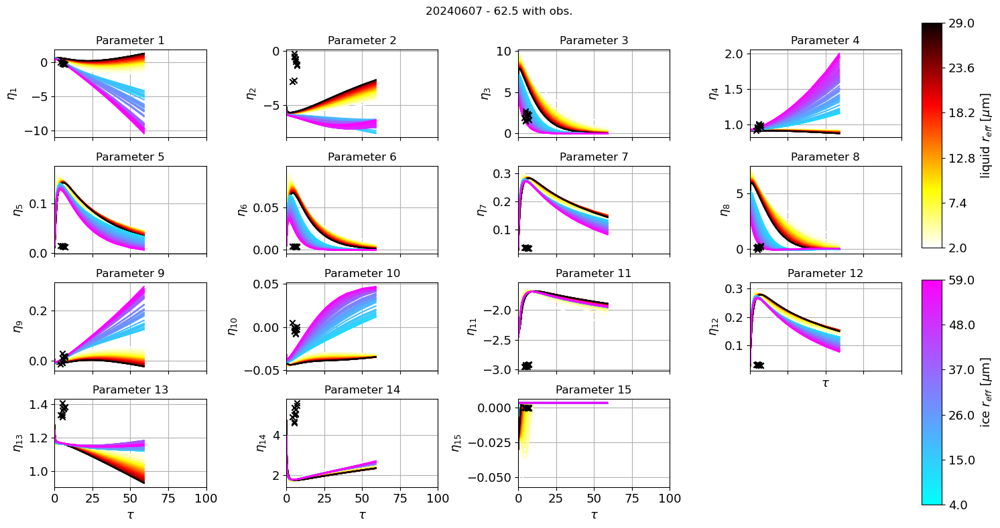

In [44]:
for i,ll in enumerate(lut):
    if len(lut[i].par)>4:
        continue
    if not i in np.unique(idx):
        continue
    try: 
        figl,axl = Sp.plot_lut_vs_tau(lut[i],forceliq=forceliq,forceice=forceice)
    except:
        print('*** Problem with plotting of sza:{sza:02.1f}'.format(sza=ll['sza'][i]))
    try:
        ik = (idx==np.int32(i)) & (meas.utc>flt[0]) & (meas.utc<flt[1])
        npar = len(meas.par[0,:])-1
        if ik.any():
            for ai,ax in enumerate(axl[0:npar]):
                try:
                    ax.scatter(meas.tau[ik],meas.par[ik,ai],marker='x',zorder=200,color='k')
                except Exception as iee:
                    print(f'** problem inside multiple - {iee}')
    except:
        print(f"**problem plotting measurements - {i}")
    figl.suptitle(f"{datestr} - SZA:{ll['sza'][i]:02.1f}° with obs.")
    figl.savefig(fp_plots+'{datestr}_lut_withmeas_sza_{sza:02.1f}.png'.format(datestr=datestr,sza=ll['sza'][i]),
                     dpi=600,transparent=True)

## Quick summary statistics

In [45]:
igood = np.isfinite(meas.tau) & (meas.utc>flt[0]) & (meas.utc<flt[1])
print('=== Retrieval summary for {} ==='.format(datestr))
print('Total time steps : {:d}'.format(len(meas.utc)))
print('Retrieved points : {:d}  ({:.1%})'.format(igood.sum(), igood.mean()))
if igood.sum() > 0:
    liq_frac = np.nanmean(meas.phase[igood] == 0)
    print('Liquid fraction  : {:.1%}'.format(liq_frac))
    print('tau  -- median: {:.2f}  mean: {:.2f}  std: {:.2f}'.format(
        np.nanmedian(meas.tau[igood]),
        np.nanmean(meas.tau[igood]),
        np.nanstd(meas.tau[igood])))
    print('r_eff -- median: {:.1f}  mean: {:.1f}  std: {:.1f} um'.format(
        np.nanmedian(meas.ref[igood]),
        np.nanmean(meas.ref[igood]),
        np.nanstd(meas.ref[igood])))

=== Retrieval summary for 20240607 ===
Total time steps : 18639
Retrieved points : 2091  (11.2%)
Liquid fraction  : 0.3%
tau  -- median: 5.00  mean: 4.66  std: 3.78
r_eff -- median: 17.0  mean: 19.6  std: 10.9 um
